In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load dataset
iris = load_iris()



In [24]:
X = pd.DataFrame(
    SimpleImputer(strategy="mean").fit_transform(X),
    columns=X.columns
)


In [19]:
X.head()

,SepalLength,PetalLength
0,5.1,1.4
1,4.9,1.4
2,4.7,1.3
3,4.6,1.5
4,5.0,1.4


In [20]:
X.isnull().sum()

SepalLength    0
PetalLength    0
dtype: int64

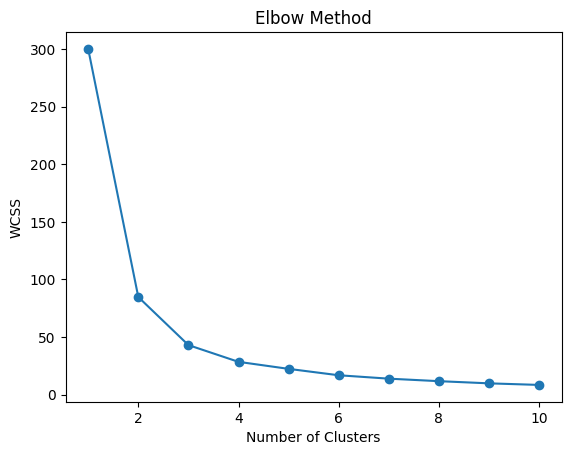

In [25]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Optimal K
k = 3

# 3. K-Means
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)


In [22]:
print("cluster centers:")
print(kmeans.cluster_centers_)

cluster centers:
[[ 1.22961906  1.02844019]
 [-1.01511749 -1.22865676]
 [ 0.03665519  0.41744409]]


Text(0.5, 1.0, 'k-mean clustering')

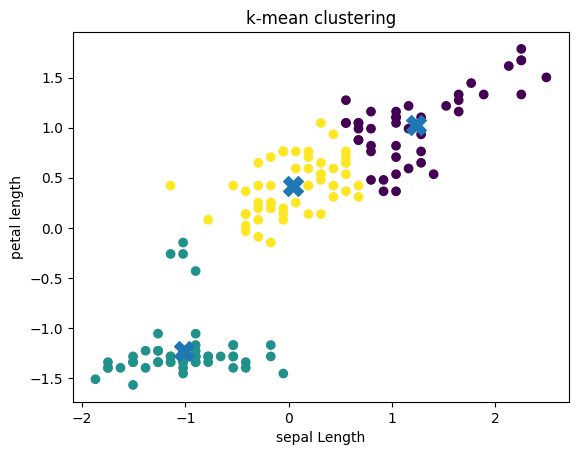

In [28]:
plt.scatter(x_scaled[:,0],
            x_scaled[:,1],
            c = labels,
            cmap = "viridis")
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    marker  = "X",
    s = 200)
plt.xlabel("sepal Length")
plt.ylabel("petal length")
plt.title("k-mean clustering")
           
            

In [30]:
score = silhouette_score(X_scaled , labels)
print("sillhoute score:", score)


sillhoute score: 0.5445015264044637


Text(0, 0.5, 'distance')

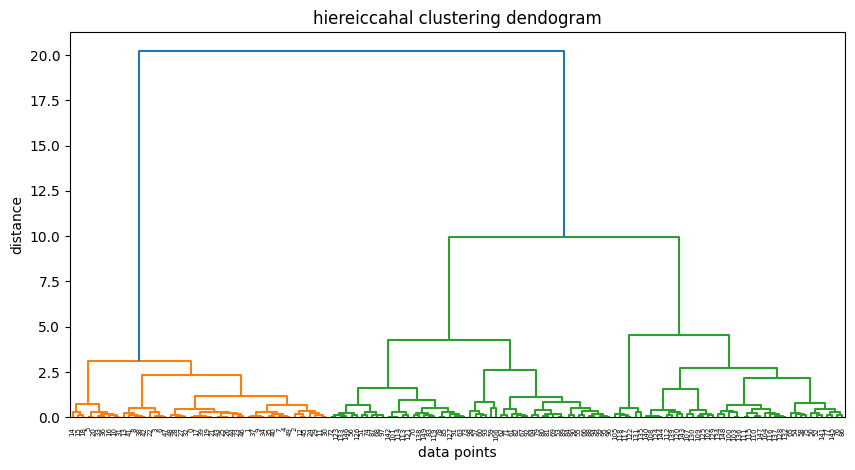

In [41]:
z = linkage(X_scaled , method = "ward")
plt.figure(figsize =(10,5))
dendrogram(z)
plt.title("hiereiccahal clustering dendogram")
plt.xlabel("data points")
plt.ylabel("distance")




In [46]:
agg = AgglomerativeClustering(
    n_clusters = k , 
    linkage  = "ward"
)

In [49]:
agg_labels= agg.fit_predict(X_scaled)
print("agglomerative labels:")
print(agg_labels)
agg_score = silhouette_score(x_scaled, 
                                 agg_labels)  

agglomerative labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 0 2 2 2 0 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2
 2 0 0 0 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


In [50]:
print("Agglomerative Silhouette Score:", agg_score)

Agglomerative Silhouette Score: 0.5359148513088201


In [ ]:
#2nd question 


In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso,LinearRegression
from sklearn.metrics import mean_squared_error , r2_score

In [78]:
data = load_diabetes()

In [87]:
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

In [85]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [86]:
df.isnull().sum()

age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

In [98]:

X = df.drop("target", axis=1)
y = df["target"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

In [99]:
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

In [100]:

# Scale
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns
)

In [101]:
def forward_selection(x, y):
    selected = []
    remaining = list(x.columns)
    best_score = -np.inf

    while remaining:
        scores = {}
        for feature in remaining:
            features = selected + [feature]
            model = LinearRegression()
            # Use local parameter 'x' instead of global 'X'
            score = cross_val_score(
                model, x[features], y, cv=5, scoring="r2"
            ).mean()
            scores[feature] = score

        best_feature = max(scores, key=scores.get)
        if scores[best_feature] > best_score:
            selected.append(best_feature)
            remaining.remove(best_feature)
            best_score = scores[best_feature]
        else:
            break

    return selected


forward_features = forward_selection(X_train, y_train)
print("Forward Selection:", forward_features)

Forward Selection: ['bmi', 's5', 's1', 'bp', 'sex', 's2']


In [102]:
def backward_elimination(x, y):
    selected = list(x.columns)
    model = LinearRegression()
    best_score = cross_val_score(model, x[selected], y, cv=5, scoring="r2").mean()

    while len(selected) > 1:
        scores = {}
        for feature in selected:
            features = [f for f in selected if f != feature]
            score = cross_val_score(
                model, x[features], y, cv=5, scoring="r2"
            ).mean()
            scores[feature] = score

        remove_feature = max(scores, key=scores.get)
        new_score = scores[remove_feature]

        if new_score >= best_score:
            selected.remove(remove_feature)
            best_score = new_score
        else:
            break

    return selected


backward_features = backward_elimination(X_train, y_train)
print("Backward Elimination:", backward_features)

Backward Elimination: ['sex', 'bmi', 'bp', 's1', 's2', 's5']


In [103]:
# Lasso Regression Grid Search
params = {"alpha": np.logspace(-4, 2, 50)}
lasso = Lasso(max_iter=10000)
grid = GridSearchCV(lasso, params, cv=5, scoring="r2")
grid.fit(X_train, y_train)

best_lasso = grid.best_estimator_
print("\nBest Alpha:", grid.best_params_["alpha"])

# Coefficients
coefficients = pd.Series(best_lasso.coef_, index=X.columns)
print("\nLasso Coefficients:\n", coefficients)

lasso_features = coefficients[coefficients != 0].index.tolist()
zero_features = coefficients[coefficients == 0].index.tolist()

print("\nLasso Selected Features:", lasso_features)
print("Zero Coefficient Features:", zero_features)

# Performance Evaluation
y_pred = best_lasso.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMSE:", mse)
print("R2 Score:", r2)


Best Alpha: 0.47148663634573945

Lasso Coefficients:
 age    -0.871300
sex   -10.650200
bmi    27.718853
bp     13.446262
s1    -10.174521
s2     -0.000000
s3     -8.800362
s4      3.254424
s5     28.021570
s6      1.793797
dtype: float64

Lasso Selected Features: ['age', 'sex', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6']
Zero Coefficient Features: ['s2']

MSE: 3433.108590105614
R2 Score: 0.3305075188449109


feature comparision
Forward Selection:
['bmi', 's5', 's1', 'bp', 'sex', 's2']

Backward Elimination:
['sex', 'bmi', 'bp', 's1', 's2', 's5']

Lasso:
['age', 'sex', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6']


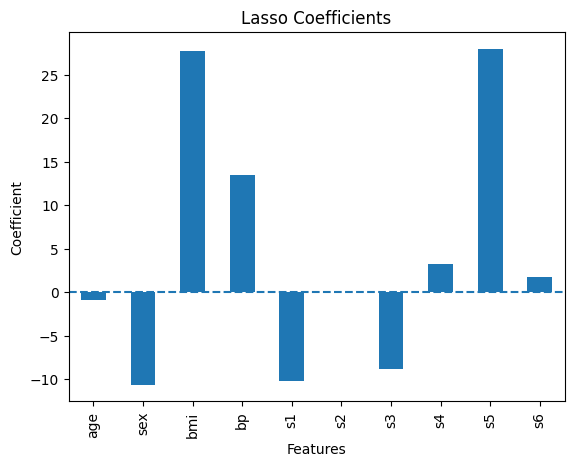

In [104]:
# 6. Compare all methods
print("feature comparision")

print("Forward Selection:")
print(forward_features)

print("\nBackward Elimination:")
print(backward_features)

print("\nLasso:")
print(lasso_features)


# Lasso coefficient plot
coefficients.plot(kind="bar")

plt.axhline(0, linestyle="--")
plt.title("Lasso Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.show()